# Text Embeddings & Visualization

Build and compare three embedding approaches:
- TF-IDF (sparse, for traditional ML)
- Word2Vec (dense word-level)
- Sentence Transformer (dense sentence-level)

In [4]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE

from config import (
    TRAIN_CSV, VAL_CSV, TEST_CSV,
    TFIDF_MAX_FEATURES, TFIDF_NGRAM_RANGE,
    W2V_VECTOR_SIZE, W2V_WINDOW, W2V_MIN_COUNT, W2V_EPOCHS,
    SENTENCE_MODEL_NAME, RANDOM_STATE
)
from src.embeddings import build_tfidf, train_word2vec, get_document_vectors, encode_sentences

# Load processed data
train = pd.read_csv(TRAIN_CSV)
val = pd.read_csv(VAL_CSV)
test = pd.read_csv(TEST_CSV)

print(f"Train: {len(train)} | Val: {len(val)} | Test: {len(test)}")

# Fill NaN in text columns (empty strings become NaN when saved/loaded from CSV)
for split in [train, val, test]:
    split["review_clean"] = split["review_clean"].fillna("")
    split["review_heavy"] = split["review_heavy"].fillna("")

Train: 6226 | Val: 1335 | Test: 1335


## 1. TF-IDF

In [5]:
# Build TF-IDF — fit ONLY on train to avoid data leakage
tfidf_vectorizer, X_train_tfidf = build_tfidf(
    train["review_heavy"],
    max_features=TFIDF_MAX_FEATURES,
    ngram_range=TFIDF_NGRAM_RANGE
)

# Transform val and test (no fitting!)
X_val_tfidf = tfidf_vectorizer.transform(val["review_heavy"])
X_test_tfidf = tfidf_vectorizer.transform(test["review_heavy"])

print(f"TF-IDF matrix shapes:")
print(f"  Train: {X_train_tfidf.shape}")
print(f"  Val:   {X_val_tfidf.shape}")
print(f"  Test:  {X_test_tfidf.shape}")

# Top features
feature_names = tfidf_vectorizer.get_feature_names_out()
print(f"\nVocabulary size: {len(feature_names)}")
print(f"Sample features: {list(feature_names[:10])}")

TF-IDF matrix shapes:
  Train: (6226, 5000)
  Val:   (1335, 5000)
  Test:  (1335, 5000)

Vocabulary size: 5000
Sample features: ['aaa', 'aaa game', 'abandoned', 'ability', 'able', 'able get', 'able play', 'absolute', 'absolutely', 'absolutely fantastic']


## 2. Word2Vec

In [6]:
# Tokenize texts for Word2Vec
train_tokens = train["review_heavy"].str.split().tolist()

# Train Word2Vec on training data
w2v_model = train_word2vec(
    train_tokens,
    vector_size=W2V_VECTOR_SIZE,
    window=W2V_WINDOW,
    min_count=W2V_MIN_COUNT,
    epochs=W2V_EPOCHS
)

print(f"Vocabulary size: {len(w2v_model.wv)}")
print(f"Vector dimension: {w2v_model.vector_size}")

# Find similar words
print("\nWords most similar to 'fun':")
for word, score in w2v_model.wv.most_similar("fun", topn=5):
    print(f"  {word}: {score:.3f}")

print("\nWords most similar to 'boring':")
for word, score in w2v_model.wv.most_similar("boring", topn=5):
    print(f"  {word}: {score:.3f}")

Vocabulary size: 7145
Vector dimension: 100

Words most similar to 'fun':
  enjoyable: 0.919
  quite: 0.890
  solo: 0.860
  chill: 0.842
  addictive: 0.842

Words most similar to 'boring':
  repetitive: 0.933
  used: 0.896
  stretch: 0.895
  little: 0.890
  grindy: 0.888


## 3. Sentence Transformer

In [7]:
# Encode training reviews with Sentence Transformer
# This may take a few minutes on CPU
st_model, train_embeddings = encode_sentences(
    train["review_clean"],
    model_name=SENTENCE_MODEL_NAME
)

print(f"Sentence embeddings shape: {train_embeddings.shape}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

c:\Users\user\steam-reviews-nlp\venv\Lib\site-packages\huggingface_hub\file_download.py:141: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\user\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/98 [00:01<?, ?it/s]

Sentence embeddings shape: (6226, 384)


## 4. t-SNE Visualization

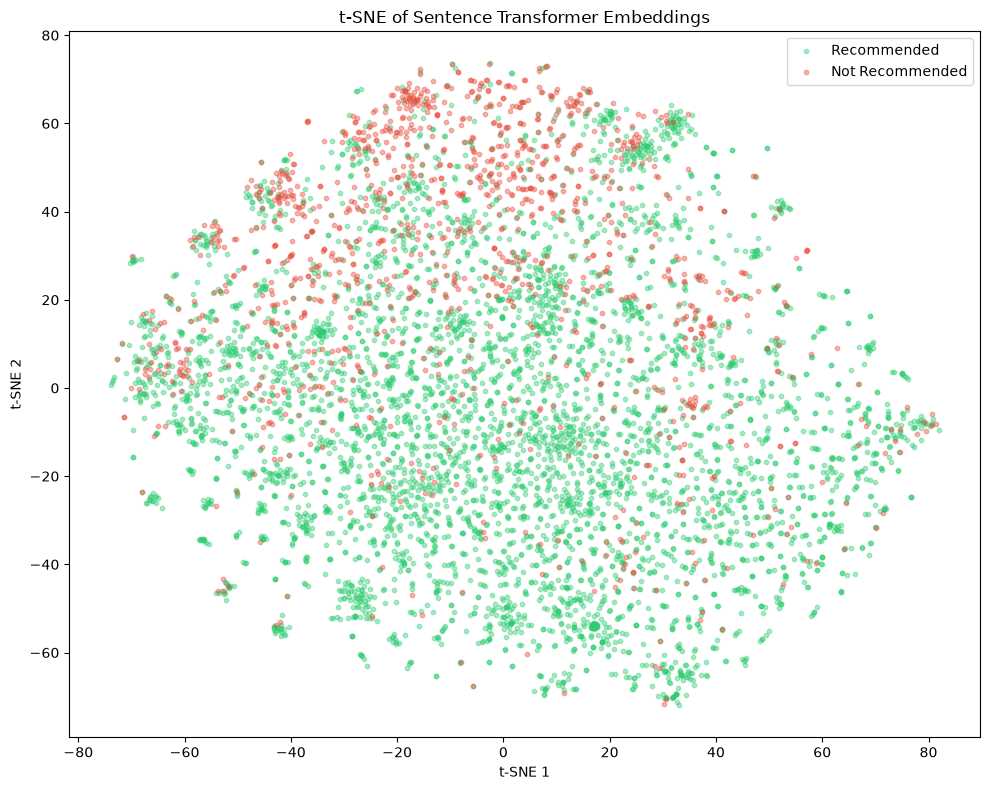

In [8]:
# t-SNE on Sentence Transformer embeddings (takes 1-2 minutes)
tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30)
embeddings_2d = tsne.fit_transform(train_embeddings)

# Plot
fig, ax = plt.subplots(figsize=(10, 8))
labels = train["recommendation"].values
colors = {"Recommended": "#2ecc71", "Not Recommended": "#e74c3c"}

for label in ["Recommended", "Not Recommended"]:
    mask = labels == label
    ax.scatter(
        embeddings_2d[mask, 0], embeddings_2d[mask, 1],
        c=colors[label], label=label, alpha=0.4, s=10
    )

ax.set_title("t-SNE of Sentence Transformer Embeddings")
ax.legend()
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
plt.tight_layout()
plt.show()

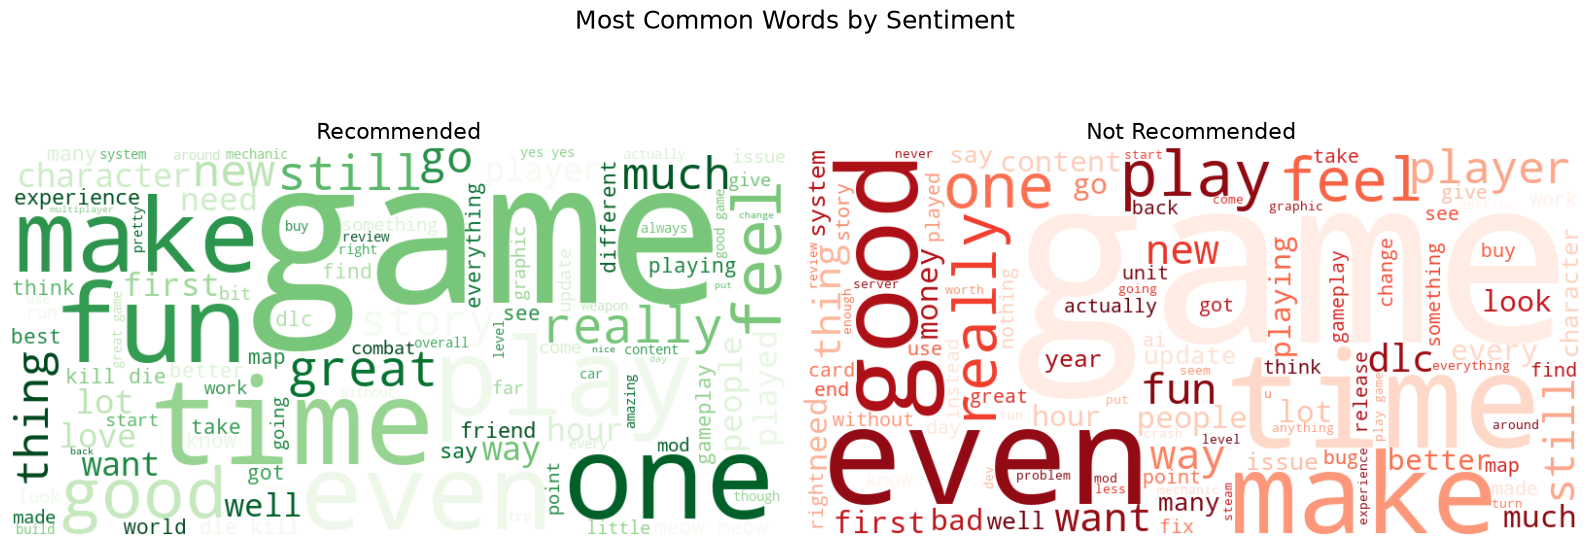

In [14]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, label, color in zip(axes, ["Recommended", "Not Recommended"], ["Greens", "Reds"]):
    text = " ".join(train[train["recommendation"] == label]["review_heavy"])
    wc = WordCloud(width=800, height=400, background_color="white", colormap=color, max_words=100)
    wc.generate(text)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(label, fontsize=16)
    ax.axis("off")

plt.suptitle("Most Common Words by Sentiment", fontsize=18, y=1.02)
plt.tight_layout()
plt.show()

## Embeddings Summary

| Method | Dimensions | Fitted on | Used by |
|--------|-----------|-----------|---------|
| TF-IDF | 5,000 (sparse) | Train only | Logistic Regression, XGBoost |
| Word2Vec | 100 (dense) | Train only | Visualization, similarity |
| Sentence Transformer | 384 (dense) | Pre-trained (no fitting) | t-SNE, BERTopic, RAG (FAISS) |

Key observations:
- Word2Vec learns meaningful word relationships (fun ↔ enjoyable, boring ↔ repetitive)
- t-SNE shows partial separation between Recommended/Not Recommended clusters
- TF-IDF fitted on train only to prevent data leakage